# xhs49-1b_1p Cell Graph

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 29.01.2024
- Date of Last Modification: 29.01.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [58]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [59]:
import sys
sys.path.append("../../utils")

In [60]:
import logging
import os
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split

from nichejepa.datasets import prepare_dataset
from nichejepa.infer import infer
from nichejepa.train import train
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [61]:
# Set params
dataset = 'xhs49-1b_1p'
tokenizer = 'cell_graph'
load_timestamp = None
read_checkpoint = 'nichejepa-ep300.pth.tar' # 'nichejepa-ep300.pth.tar' # 'nichejepa-ep5.pth.tar', None
niche_key = 'niche_name'

In [62]:
model_config_folder_path = '../../config/model'
artifacts_folder_path = '../../artifacts'
datasets_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

In [63]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{tokenizer}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['state']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

INFO:root:Loaded parameters from YAML file.


{'data': {'dataset_name': 'xhs49-1b_1p',
  'raw_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/silver/xhs49-1b_1p',
  'token_dict_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl',
  'tokenized_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/gold/cell-graph-tokenizer/xhs49-1b_1p/xhs49-1b_1p_32_None_None_None_None_None_shifted_log_knn_6_1792.dataset',
  'tokenizer_type': 'cell_graph',
  'random_state': 0,
  'sample_subset': False,
  'split': 0,
  'test_batch_ids': ['49_batch0'],
  'stratify': False,
  'seq_len_cell': 256,
  'seq_len_neighborhood': 1536,
  'n_segments': 7,
  'sampling_strategy': None,
  'batch_size': 32,
  'num_workers': 24,
  'pin_memory': True},
 'meta': {'add_cls': False,
  'gt_type': 'rank',
  'enc_depth': 3,
  'enc_emb_dim': 768,
  'pred_depth': 1,
  'pred_emb_dim': 768,
  'special_tokens': [],
  'pos_learnable': False,
  'seg_learnable': False,
  'use_bfloat16': True,
  'use_flas

In [64]:
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'../../artifacts/xhs49-1b_1p/31012025_163904_857'

## 1.3 Create Train & Test Dataset

In [65]:
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

Dataset({
    features: ['cell_degrees', 'cell_total_counts', 'cell_n_probed_genes', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 0
})

In [66]:
# item = test_dataset[0]

## 1.4 Run INIT Distributed

In [67]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=random.randint(40000, 50000))
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2. Model Training

In [ ]:
### Train model
train(params,
      train_dataset,
      test_dataset,
      save_folder_path=folder_path)

# 3. Analysis

## 3.1 Run Model Inference

In [68]:
# Set inference params
layer = params['meta']['enc_depth'] - 1
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
latent_leiden_resolution = 0.13
latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [69]:
# Get gene tokens that overlap between gene panels to obtain excluded tokens from aggregation
if exclude_unshared_tokens:
    gene_panel_gene_mapping_file_path = '/lustre/scratch126/cellgen/team361/am84/NicheJEPA/datasets/am84/tokenizer/cell-neighborhood-tokenizer/merfish_mouse_brain_8-batch_2-gene-panels/gene_panel_ID_to_gene_panel_dict.pkl'
    token_dictionary_file_path = '/lustre/scratch126/cellgen/team361/am84/NicheJEPA/datasets/am84/tokenizer/cell-neighborhood-tokenizer/merfish_mouse_brain_8-batch_2-gene-panels/token_dictionary_no_cls_no_sep.pkl'
    
    with open(gene_panel_gene_mapping_file_path, 'rb') as file:
        gene_panel_gene_mapping = pickle.load(file)
    
    with open(token_dictionary_file_path, 'rb') as file:
        token_dictionary = pickle.load(file)
    
    genes_panel0 = set(gene_panel_gene_mapping[0])
    genes_panel1 = set(gene_panel_gene_mapping[1])
    
    overlapping_genes = list(genes_panel0.intersection(genes_panel1))
    
    overlapping_gene_tokens = [token_dictionary[gene] for gene in overlapping_genes if gene in token_dictionary]
    
    excluded_tokens = list(set(token_dictionary.values()) - set(overlapping_gene_tokens))

In [70]:
# Run model inference
adata = infer(params,
              test_dataset, # train_dataset, test_dataset
              load_folder_path=folder_path,
              agg_type=agg_type,
              agg_excluded_tokens=excluded_tokens if exclude_unshared_tokens else None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[])

# Save adata
adata.write(f'{folder_path}/adata_{agg_type}'
            f'{"_shared_genes" if exclude_unshared_tokens and "cls" not in agg_type else ("_all_genes" if "cls" not in agg_type else "")}.h5ad')

INFO:root:GeneTransformerRankEncoder(
  (token_embed): Embedding(23407, 768, padding_idx=0)
  (seg_embed): Embedding(113, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (pos_embed): Embedding(1793, 768, padding_idx

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 24 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/helper.py:78: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `we

## 3.2 Plot Embeddings

In [71]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

Number of latent clusters 9
NMI is 0.22170734214392412. ARI is 0.12577903113626343.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
... storing 'batch' as categorical
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax =

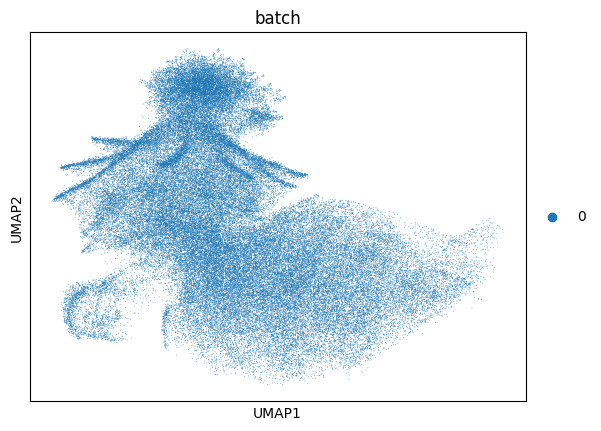

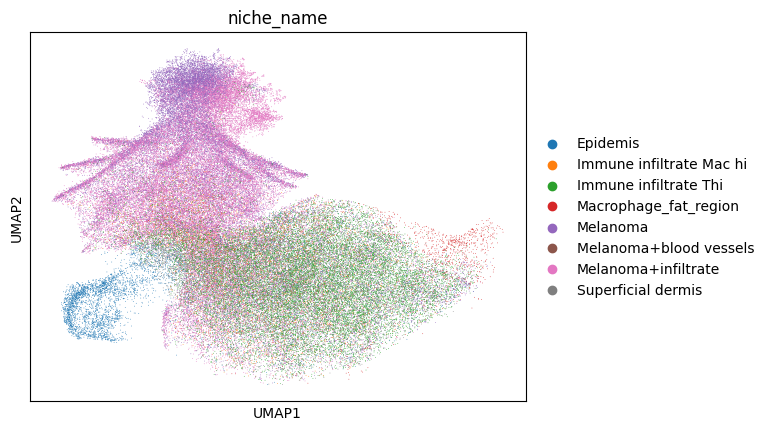

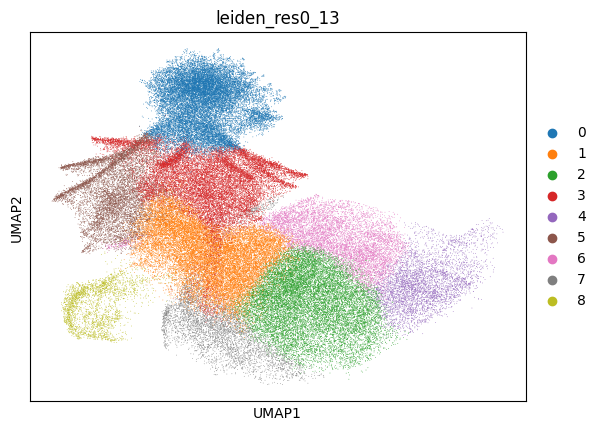

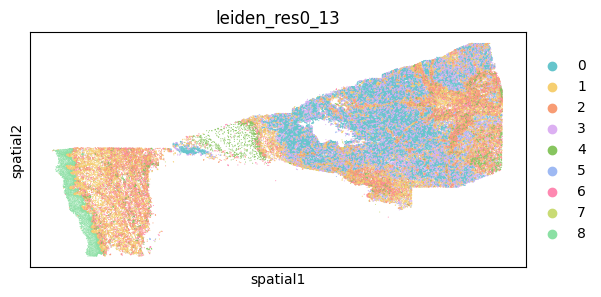

In [72]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.4
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001
    break

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

# Plot niches in tissue
spot_sizes = [20, 20, 20]
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

Number of latent clusters 7
NMI is 0.19036118301731544. ARI is 0.22012711912814759.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  

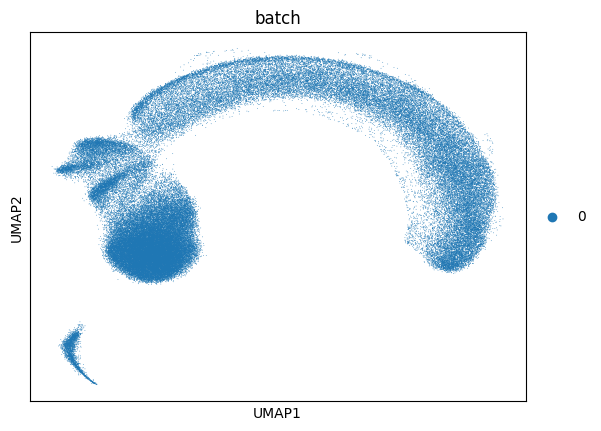

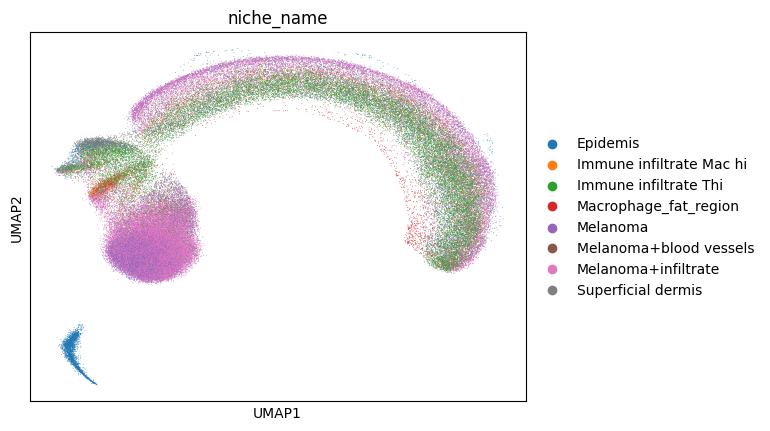

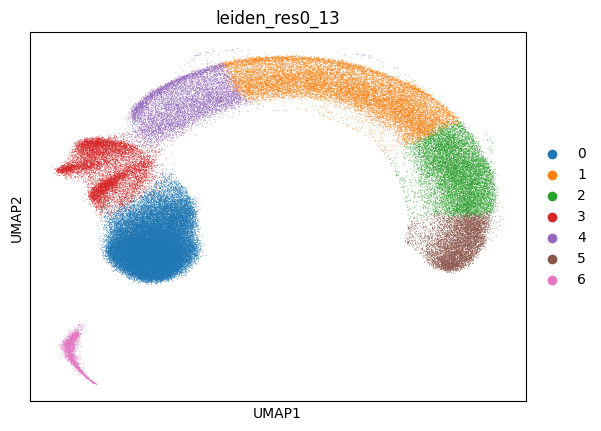

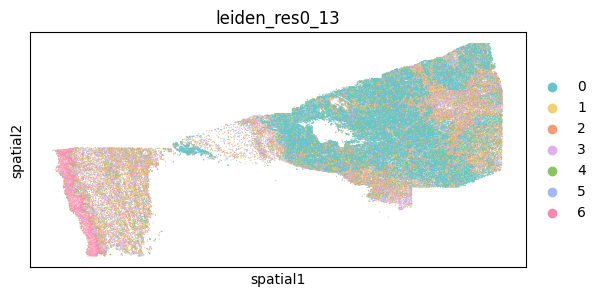

In [73]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{layer}',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.4
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001
    break

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

# Plot niches in tissue
spot_sizes = [20, 20, 20]
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

In [ ]:
spot_sizes = [20, 20, 20]
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])
    #sq.pl.spatial_scatter(adata_batch,
    #                      color=latent_cluster_key,
    #                      shape=None)

In [ ]:
# Compute metrics
labels = adata.obs['niche_type']
labels_pred = adata.obs[latent_cluster_key]

nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)

print(f'NMI is {nmi}. ARI is {ari}.')

## 3.3 Plot Embedding Similarity Stats

## 3.4 Compute Metrics

In [ ]:
benchmarking_artifacts_folder_path

In [ ]:
# Compute metrics
labels = adata.obs['niche_type']
labels_pred = adata.obs[latent_cluster_key]

nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)

print(f'NMI is {nmi}. ARI is {ari}.')

In [ ]:
metrics_df = pd.DataFrame({'Metric': ['NMI', 'ARI'], 'Value': [nmi, ari]})
metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/metrics/nichejepa_task.csv', index=False)

In [ ]:
os.makedirs(f'{folder_path}/metrics', exist_ok=True)

labels = ['cell_types', 'major_brain_region']

# NMI & ARI for label cols (neighborhood embedding)
for label in labels:
    cell_type_metrics = clustering_metrics(
        adata,
        emb_key=f'neighborhood_emb_layer_{layer}',
        label_col=label)
    
    metrics_df = pd.DataFrame([cell_type_metrics])
    metrics_df.to_csv(f'{folder_path}/metrics/{label}_metrics{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.csv', index=False)

## 3.5 Plot Loss Curve

In [ ]:
df = pd.read_csv(f'{folder_path}/nichejepa_r0.csv')
df['loss'] = pd.to_numeric(df['loss'], errors='coerce')

plt.figure(figsize=(10, 6))
plt.plot(df.index,df['loss'])
plt.title('Loss Function Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.show()